# 05 — Response of ⟨VT⟩ to the selection criteria (companion paper)

**Runs:** Suite 02, simulate once, filter many. 100 candidate sets of 10⁶ injections per model are filtered on a
grid of criteria. **Feeds:** companion paper, Fig. 6.

**Rule to keep in mind.** As in survey_sim, a source passes the evolution test if it fades at least as fast as the
minimum fade rate **or** rises at least as fast as the minimum rise rate; 0 switches that branch off. A rise
threshold therefore *adds* a way to pass, and fade rate = 0 (with rise off) means no evolution test at all.

In [1]:
# ---------------------------------------------------------------- settings
SNAPSHOT = "latest"      # "latest" | time stamp or prefix | "newest" | path/to/snapshot.zip | "live"
SAVE_FIGURES = False     # write PDF+PNG of each figure to figures/05/
# ---------------------------------------------------------------------------
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "knrates").is_dir())
sys.path.insert(0, str(ROOT))
for _m in [m for m in list(sys.modules) if m.split(".")[0] == "knrates"]:
    del sys.modules[_m]   # always import the repository copy (a kernel may predate a git pull)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from knrates import notebook as NB, figures as F, analysis as A, plotting as P, literature as L
from knrates.stats import summarize_runs

ctx = NB.setup(SNAPSHOT, save_figures=SAVE_FIGURES, fig_dir="figures/05")
runs, lim, M = ctx.runs, ctx.lim, ctx.models
FIX, ISO = "Bu2026Fixed", "Bu2026Vary"

knrates_results_latest.zip (created 20261111T024800Z, git d7af6653)
models: Bu2026Fixed, Bu2026Vary


## Are all candidate sets compatible with the current envelope?

In [2]:
import json
cand = ctx.snap["suite02_candidate_runs"].copy()
cand["loose_b"] = cand.loose_criteria_json.apply(lambda s: json.loads(s).get("min_galactic_lat"))
ok = (cand.loose_b == 15.0) & (cand.z_max == 0.15)
display(cand.groupby(["model", ok.rename("compatible")]).size().rename("candidate sets").to_frame())
NB.finding("All candidate sets are compatible." if ok.all() else f"{(~ok).sum()} incompatible candidate sets are present: re-simulate them.")

,,candidate sets
model,compatible,
Bu2026Fixed,True,101
Bu2026Vary,True,101


> **Result.** All candidate sets are compatible.

## Cross-check against Suite 01 at identical criteria

In [3]:
fid = ctx.snap["suite02_fiducial"].set_index("model")
x = pd.DataFrame({"vt_suite02": fid.effective_vt_gpc3_yr, "vt_suite01": lim.vt_gpc3_yr}).dropna()
x["ratio"] = x.vt_suite02 / x.vt_suite01; display(x.round(4))
NB.finding(f"The filter recovers {100 * x.ratio.min():.0f}–{100 * x.ratio.max():.0f}% of survey_sim's ⟨VT⟩: it fits fade slopes "
           "to the noisy stored photometry, while survey_sim uses noiseless magnitudes. All results below are relative to "
           "the Suite 02 fiducial point, so this offset cancels.")

,vt_suite02,vt_suite01,ratio
model,,,
Bu2026Fixed,0.0138,0.0156,0.8838
Bu2026Vary,0.0041,0.0045,0.9144


> **Result.** The filter recovers 88–91% of survey_sim's ⟨VT⟩: it fits fade slopes to the noisy stored photometry, while survey_sim uses noiseless magnitudes. All results below are relative to the Suite 02 fiducial point, so this offset cancels.

## One criterion at a time (Fig. 6 shows six of these panels)

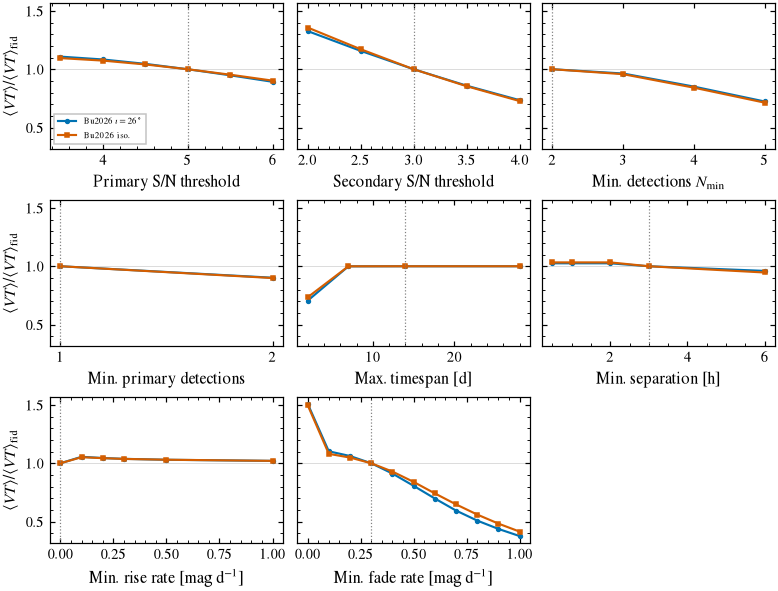

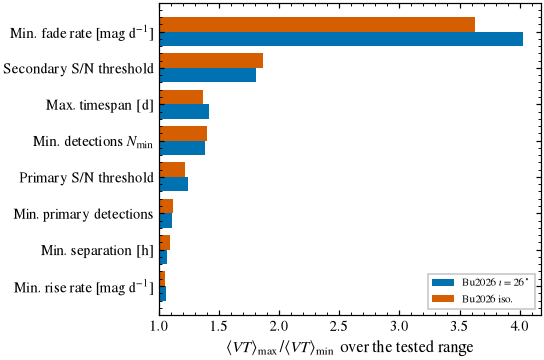

model,Bu2026Fixed,Bu2026Vary
criterion,,
max_timespan_days,0,0
min_fade_rate,-0.22,-0.18
min_time_separation_hours,-0.06,-0.08
snr_threshold,-0.49,-0.44
snr_threshold_secondary,-0.89,-0.94


> **Result.** Largest range: min_fade_rate (4.0×). Largest local sensitivity (elasticity d ln⟨VT⟩ / d ln x): snr_threshold_secondary (-0.89). Both models respond almost identically, so the response is set by the cadence, not the kilonova model.

In [4]:
s1 = ctx.snap["suite02_slices_1d"]
fig = F.criteria_one_at_a_time(s1, fid, list(A.FIDUCIAL_CRITERIA)); ctx.save(fig, "one_at_a_time"); plt.show()
resp = A.criteria_response(s1, fid)
fig = F.criteria_ranking(resp); ctx.save(fig, "ranking"); plt.show()
display(resp.pivot(index="criterion", columns="model", values="elasticity").dropna(how="all").round(2))
r = resp[resp.model == FIX].set_index("criterion")
NB.finding(f"Largest range: {r.vt_max_over_min.idxmax()} ({r.vt_max_over_min.max():.1f}×). Largest local sensitivity "
           f"(elasticity d ln⟨VT⟩ / d ln x): {r.elasticity.abs().idxmax()} ({r.elasticity[r.elasticity.abs().idxmax()]:.2f}). "
           "Both models respond almost identically, so the response is set by the cadence, not the kilonova model.")

## Two criteria together

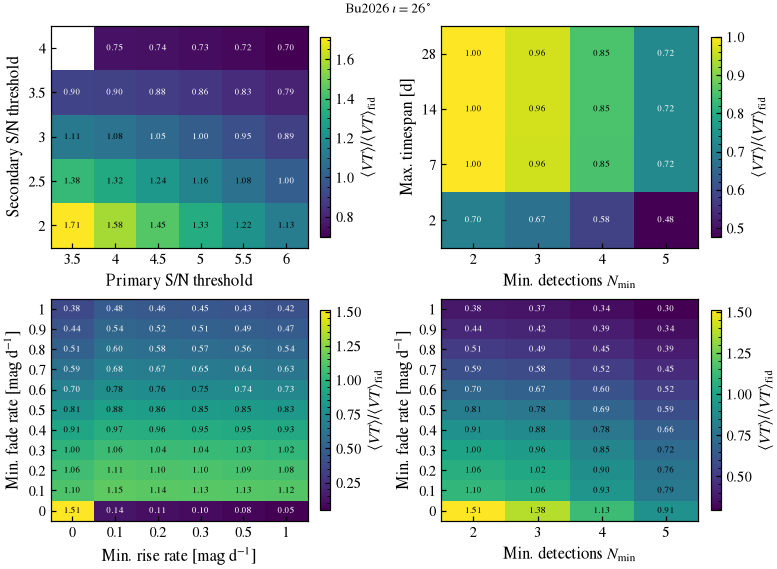

In [5]:
fig = F.criteria_pairs(ctx.snap["suite02_slices_2d"], fid, FIX); ctx.save(fig, "pairs"); plt.show()

## Named search strategies

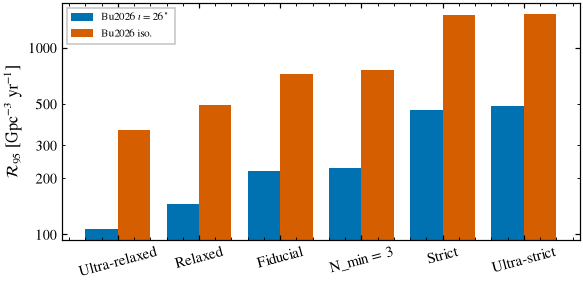

,snr_threshold,snr_threshold_secondary,min_detections,min_detections_primary,max_timespan_days,min_time_separation_hours,min_rise_rate,min_fade_rate,min_galactic_lat
regime,,,,,,,,,
Ultra-relaxed,4,2.5,2,1,28,3,0,0,15
Relaxed (S03-like),4,2.5,2,1,28,1,0,0.1,15
Fiducial,5,3,2,1,14,3,0,0.3,15
N_min = 3,5,3,3,1,14,3,0,0.3,15
Strict (S03-like),6,4,3,2,7,6,0,0.5,15
Ultra-strict,6,4,3,1,7,3,0,0.6,15


> **Result.** From the loosest to the strictest strategy the fixed-angle limit changes 4.5× (107 → 486 Gpc⁻³ yr⁻¹).

In [6]:
nc = ctx.snap["suite02_named_configs"]
fig = F.named_regimes(nc); ctx.save(fig, "named_regimes"); plt.show()
t = nc.pivot(index="regime", columns="model", values="rate_upper_95")
display(nc.drop_duplicates("regime").set_index("regime")[list(A.FIDUCIAL_CRITERIA)])
NB.finding(f"From the loosest to the strictest strategy the fixed-angle limit changes {t[FIX].max() / t[FIX].min():.1f}× "
           f"({t[FIX].min():.0f} → {t[FIX].max():.0f} Gpc⁻³ yr⁻¹).")